# Global Restaurant Dataset — KPI Analysis (Sprint 1)

**Pipeline:** CSV → Python (Pandas EDA/Cleaning) → Cleaned CSV → MySQL → Power BI

> Note: the project board title says "Global population," but the uploaded file is actually a global **restaurants** dataset (9,551 restaurants across 15 countries / 141 cities, with ratings, cuisines, cost, and delivery info). This notebook is built around that data.

**Steps in this notebook:**
1. Load dataset
2. Exploratory Data Analysis (EDA)
3. Data Cleaning
4. EDA Visuals (matplotlib / seaborn)
5. Export cleaned dataset to CSV
6. Load cleaned data into MySQL (mysql-connector-python)


## 1. Imports

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("whitegrid")
os.makedirs("charts", exist_ok=True)


## 2. Load Dataset

In [7]:
RAW_PATH = r"C:\Users\aadil\Documents\SPRINT PROJECT\archive\Dataset .csv"   # <-- update if your filename/path differs
df = pd.read_csv(RAW_PATH)
print("Raw shape:", df.shape)
df.head()


Raw shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


## 3. Exploratory Data Analysis (before cleaning)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   str    
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   str    
 4   Address               9551 non-null   str    
 5   Locality              9551 non-null   str    
 6   Locality Verbose      9551 non-null   str    
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   str    
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   str    
 12  Has Table booking     9551 non-null   str    
 13  Has Online delivery   9551 non-null   str    
 14  Is delivering now     9551 non-null   str    
 15  Switch to order menu  9551 non-n

In [9]:
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
Cuisines    9
dtype: int64

Duplicate rows: 0


In [10]:
df.describe()


,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9.551000e+03,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,18.365616,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,8.791521e+06,56.750546,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,5.300000e+01,1.000000,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,3.019625e+05,1.000000,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,6.004089e+06,1.000000,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,1.835229e+07,1.000000,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,1.850065e+07,216.000000,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


## 4. Data Cleaning
- Standardize column names to snake_case (also makes MySQL loading easier)
- Drop `switch_to_order_menu` (constant column, no analytical value)
- Fill missing `cuisines` with `"Not Available"`
- Remove duplicate rows
- Flag rated vs not-rated restaurants (rating = 0 with 0 votes = not yet rated)
- Convert Yes/No columns to booleans
- Trim whitespace on text columns


In [11]:
# a) Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.replace(" ", "_")
    .str.replace(r"[^\w]", "", regex=True)
    .str.lower()
)

# b) Drop columns with no analytical value
if "switch_to_order_menu" in df.columns:
    df.drop(columns=["switch_to_order_menu"], inplace=True)

# c) Handle missing values
if "cuisines" in df.columns:
    df["cuisines"] = df["cuisines"].fillna("Not Available")

# d) Remove duplicate rows
df.drop_duplicates(inplace=True)

# e) Flag rated vs not-rated (rather than deleting rows)
df["is_rated"] = np.where(df["votes"] > 0, "Rated", "Not Rated")

# f) Convert Yes/No text columns to booleans
yn_cols = ["has_table_booking", "has_online_delivery", "is_delivering_now"]
for c in yn_cols:
    if c in df.columns:
        df[c] = df[c].map({"Yes": True, "No": False})

# g) Trim whitespace on text columns
text_cols = df.select_dtypes(include="str").columns
for c in text_cols:
    df[c] = df[c].astype(str).str.strip()

# h) Reset index
df.reset_index(drop=True, inplace=True)

print("Cleaned shape:", df.shape)


Cleaned shape: (9551, 21)


## 5. EDA Visuals (matplotlib / seaborn)

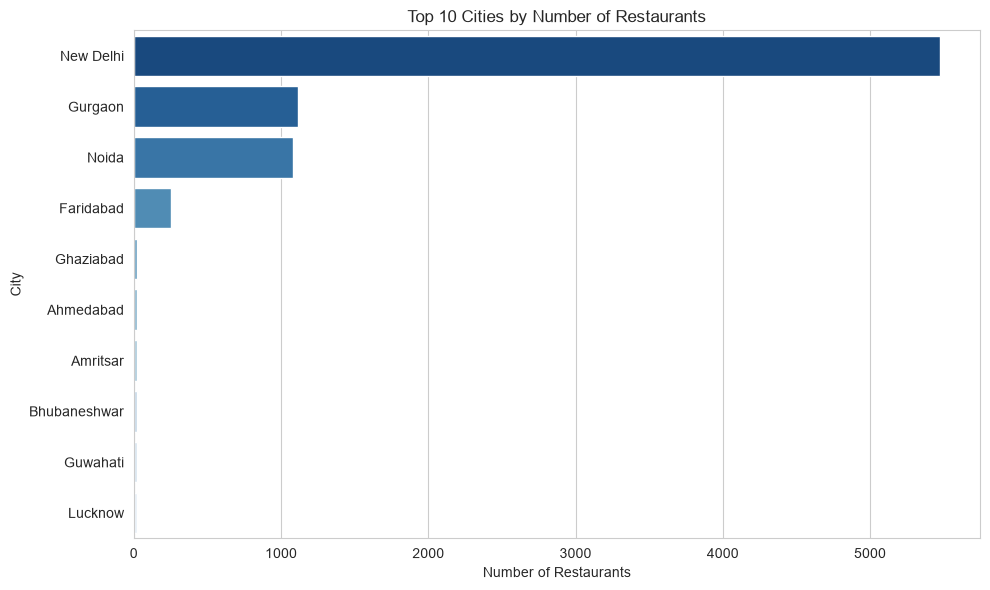

In [12]:
plt.figure(figsize=(10, 6))
top_cities = df["city"].value_counts().head(10)
sns.barplot(x=top_cities.values, y=top_cities.index, hue=top_cities.index, palette="Blues_r", legend=False)
plt.title("Top 10 Cities by Number of Restaurants")
plt.xlabel("Number of Restaurants")
plt.ylabel("City")
plt.tight_layout()
plt.savefig("charts/top10_cities.png", dpi=150)
plt.show()


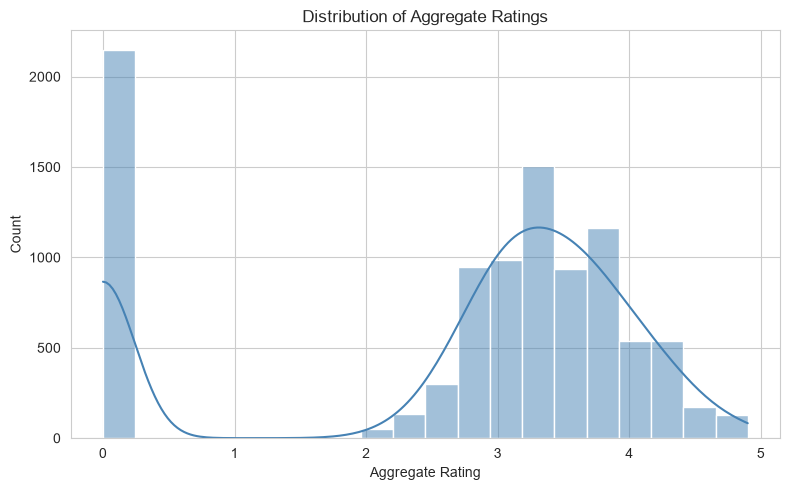

In [13]:
plt.figure(figsize=(8, 5))
sns.histplot(df["aggregate_rating"], bins=20, kde=True, color="steelblue")
plt.title("Distribution of Aggregate Ratings")
plt.xlabel("Aggregate Rating")
plt.tight_layout()
plt.savefig("charts/rating_distribution.png", dpi=150)
plt.show()


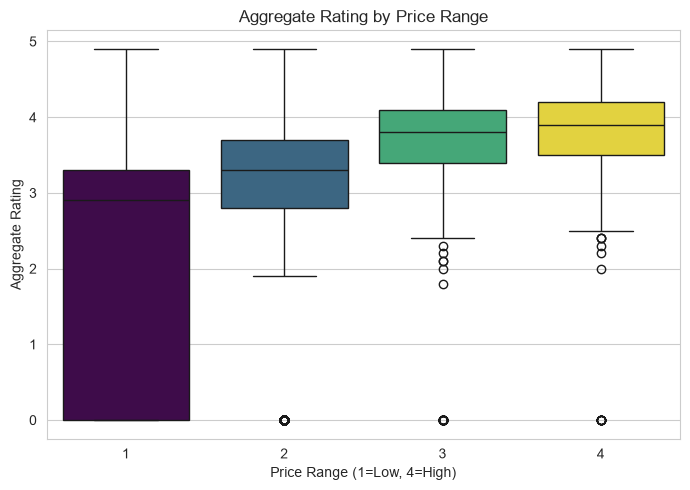

In [14]:
plt.figure(figsize=(7, 5))
sns.boxplot(x="price_range", y="aggregate_rating", data=df, hue="price_range", palette="viridis", legend=False)
plt.title("Aggregate Rating by Price Range")
plt.xlabel("Price Range (1=Low, 4=High)")
plt.ylabel("Aggregate Rating")
plt.tight_layout()
plt.savefig("charts/price_vs_rating.png", dpi=150)
plt.show()


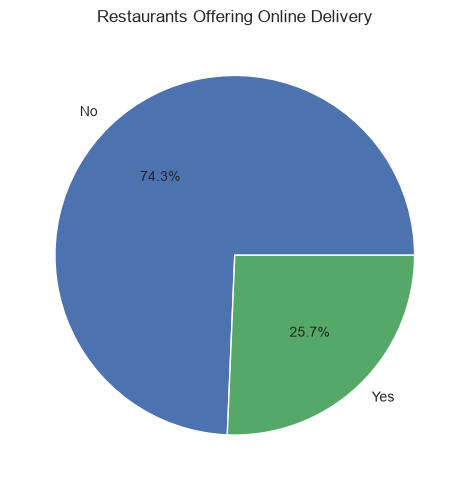

In [15]:
plt.figure(figsize=(6, 5))
df["has_online_delivery"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", labels=["No", "Yes"], colors=["#4C72B0", "#55A868"]
)
plt.title("Restaurants Offering Online Delivery")
plt.ylabel("")
plt.tight_layout()
plt.savefig("charts/online_delivery_share.png", dpi=150)
plt.show()


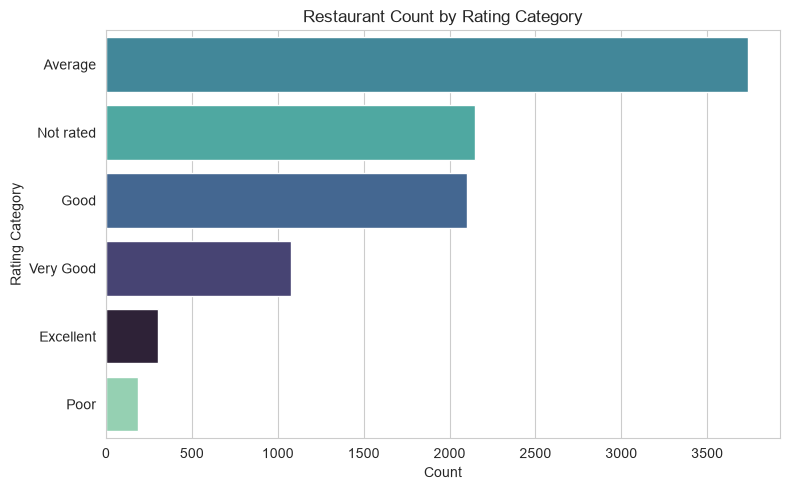

In [16]:
plt.figure(figsize=(8, 5))
order = df["rating_text"].value_counts().index
sns.countplot(y="rating_text", data=df, order=order, hue="rating_text", palette="mako", legend=False)
plt.title("Restaurant Count by Rating Category")
plt.xlabel("Count")
plt.ylabel("Rating Category")
plt.tight_layout()
plt.savefig("charts/rating_text_breakdown.png", dpi=150)
plt.show()


## 6. Export Cleaned Dataset

In [17]:
OUTPUT_PATH = "global_cleaned.csv"
df.to_csv(OUTPUT_PATH, index=False)
print(f"Cleaned dataset exported -> {OUTPUT_PATH}  ({df.shape[0]} rows, {df.shape[1]} cols)")


Cleaned dataset exported -> global_cleaned.csv  (9551 rows, 21 cols)


## 7. Load Cleaned Data into MySQL
Requires `mysql-connector-python` (`pip install mysql-connector-python`) and a running MySQL server. Edit `USER` / `PASSWORD` before running this cell.

In [18]:
import mysql.connector
from mysql.connector import Error

HOST = "localhost"
PORT = 3306
USER = "root"
PASSWORD = "10032004"   # <-- change this
DATABASE = "global_kpi_db"
TABLE = "cleaned_data"

def infer_sql_type(dtype):
    if pd.api.types.is_integer_dtype(dtype):
        return "BIGINT"
    if pd.api.types.is_float_dtype(dtype):
        return "DOUBLE"
    if pd.api.types.is_bool_dtype(dtype):
        return "BOOLEAN"
    return "TEXT"

try:
    # Create database
    conn = mysql.connector.connect(host=HOST, port=PORT, user=USER, password=PASSWORD)
    cur = conn.cursor()
    cur.execute(f"CREATE DATABASE IF NOT EXISTS `{DATABASE}`")
    conn.commit()
    cur.close()
    conn.close()

    # Create table + load data
    conn = mysql.connector.connect(host=HOST, port=PORT, user=USER, password=PASSWORD, database=DATABASE)
    cur = conn.cursor()

    cols_sql = ", ".join(f"`{col}` {infer_sql_type(dt)}" for col, dt in df.dtypes.items())
    cur.execute(f"DROP TABLE IF EXISTS `{TABLE}`")
    cur.execute(f"CREATE TABLE `{TABLE}` ({cols_sql})")
    conn.commit()

    placeholders = ", ".join(["%s"] * len(df.columns))
    col_names = ", ".join(f"`{c}`" for c in df.columns)
    insert_sql = f"INSERT INTO `{TABLE}` ({col_names}) VALUES ({placeholders})"
    data = [tuple(None if pd.isna(v) else v for v in row) for row in df.itertuples(index=False)]

    batch_size = 1000
    for i in range(0, len(data), batch_size):
        cur.executemany(insert_sql, data[i:i + batch_size])
        conn.commit()
        print(f"Inserted {min(i + batch_size, len(data))}/{len(data)} rows...")

    cur.close()
    conn.close()
    print("Load complete.")
except Error as e:
    print("MySQL error:", e)


Inserted 1000/9551 rows...
Inserted 2000/9551 rows...
Inserted 3000/9551 rows...
Inserted 4000/9551 rows...
Inserted 5000/9551 rows...
Inserted 6000/9551 rows...
Inserted 7000/9551 rows...
Inserted 8000/9551 rows...
Inserted 9000/9551 rows...
Inserted 9551/9551 rows...
Load complete.
